# Notebook 01: Preprocesamiento de PM2.5

Proyecto de Aprendizaje Automático (Tecnólogo 2026). Pronóstico horario de PM2.5 en Montevideo (Curva de Maroñas y Museo Romántico).

Este notebook parte de los datos minutales originales y genera la serie horaria que usarán los notebooks siguientes (`data/processed/pm25_horario_preprocesado.csv`). Cubre los puntos: conservación del dataset original y trabajar con una copia de este, diagnóstico, top-coding, agregación horaria, partición desarrollo/test y tratamiento de faltantes.

## 1. Conservación de los datos originales

Se descarga desde el repositorio del proyecto una copia sin modificar de los datos minutales de PM2.5 (`pm25_original.csv.gz`) y se guarda en `data/raw/` en modo solo lectura. Todo el procesamiento posterior se realiza sobre copias en memoria o en `data/processed/`, de modo que el dato original queda siempre disponible y el flujo es reproducible.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from urllib.request import urlretrieve
SEED = 42
rng = np.random.default_rng(SEED)

URL_ORIGINAL = "https://raw.githubusercontent.com/trajano-carballo/paa-pronostico-pm25-montevideo/main/data/raw/pm25_original.csv.gz"

DIR_RAW = Path("data/raw")
DIR_PROC = Path("data/processed")
DIR_RAW.mkdir(parents=True, exist_ok=True)
DIR_PROC.mkdir(parents=True, exist_ok=True)

# Copia local intacta (descarga única, solo lectura)
copia = DIR_RAW / "pm25_original.csv.gz"
if not copia.exists():
    urlretrieve(URL_ORIGINAL, copia)
    copia.chmod(0o444)

df_raw = pd.read_csv(copia)
df_raw.info()
df_raw.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1314267 entries, 0 to 1314266
Data columns (total 5 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   timestamp                 1314267 non-null  object 
 1   estacion                  1314267 non-null  object 
 2   valor                     1283468 non-null  float64
 3   unidad                    1314267 non-null  object 
 4   indicador_valor_faltante  1314267 non-null  object 
dtypes: float64(1), object(4)
memory usage: 50.1+ MB


,timestamp,estacion,valor,unidad,indicador_valor_faltante
0,2024-01-01 00:00:00-03,Curva de Maroñas,122.0,ug/m3,f
1,2024-01-01 00:01:00-03,Curva de Maroñas,117.0,ug/m3,f
2,2024-01-01 00:02:00-03,Curva de Maroñas,122.0,ug/m3,f
3,2024-01-01 00:03:00-03,Curva de Maroñas,116.0,ug/m3,f
4,2024-01-01 00:04:00-03,Curva de Maroñas,104.0,ug/m3,f


## 1.1 Pasar la fecha a zona horaria de Montevideo UTC-3

In [2]:
df = df_raw.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True).dt.tz_convert("America/Montevideo")
df["faltante"] = df["valor"].isna() | df["indicador_valor_faltante"].eq("t")
df = df.sort_values(["estacion", "timestamp"]).reset_index(drop=True)

## 2. Diagnosticar la serie minutal completa.
### cada estación se diagnostica por separado, porque tienen frecuencias distintas (1 min y 2 min).

## 2.1 Faltantes: explícitos e implícitos, con duración y ubicación.

## 2.1a Faltantes explícitos
Son registros que existen en la serie (hay una fila con su timestamp) pero sin dato utilizable: el `valor` está vacío o la fila está marcada con `indicador_valor_faltante`. Se agrupan los registros consecutivos en episodios para ver cuándo ocurrieron y cuánto duraron

In [3]:
explicitos = {}
for est, g in df.groupby("estacion"):
    g = g.reset_index(drop=True)
    bloque = (g["faltante"] != g["faltante"].shift()).cumsum()
    f = g[g["faltante"]]
    explicitos[est] = (f.groupby(bloque[f.index])["timestamp"]
                       .agg(inicio="min", fin="max", n_registros="size")
                       .reset_index(drop=True))
    explicitos[est]["duracion"] = explicitos[est]["fin"] - explicitos[est]["inicio"]
    print(est, "-", len(explicitos[est]), "episodios,", int(g["faltante"].sum()), "registros")

explicitos["Curva de Maroñas"].sort_values("n_registros", ascending=False).head(10)

Curva de Maroñas - 35 episodios, 30742 registros
Museo Romántico - 7 episodios, 57 registros


,inicio,fin,n_registros,duracion
21,2025-06-02 11:40:00-03:00,2025-06-23 12:59:00-03:00,30127,21 days 01:19:00
9,2024-09-17 09:56:00-03:00,2024-09-17 10:37:00-03:00,40,0 days 00:41:00
7,2024-07-16 10:50:00-03:00,2024-07-16 11:24:00-03:00,34,0 days 00:34:00
20,2025-05-02 11:00:00-03:00,2025-05-02 11:32:00-03:00,31,0 days 00:32:00
12,2024-11-28 11:45:00-03:00,2024-11-28 12:22:00-03:00,30,0 days 00:37:00
5,2024-05-03 09:47:00-03:00,2024-05-03 10:22:00-03:00,29,0 days 00:35:00
32,2026-03-06 10:48:00-03:00,2026-03-06 11:15:00-03:00,28,0 days 00:27:00
34,2026-05-15 11:29:00-03:00,2026-05-15 11:58:00-03:00,27,0 days 00:29:00
27,2025-11-07 10:02:00-03:00,2025-11-07 10:29:00-03:00,26,0 days 00:27:00
22,2025-06-27 11:28:00-03:00,2025-06-27 11:55:00-03:00,22,0 days 00:27:00


##2.1b Faltantes implícitos
Son registros que directamente no existen: no hay fila ni marca de faltante, simplemente falta un tramo de la serie. Se detectan cuando el salto entre dos timestamps consecutivos supera lo esperable (más de 90 s en Curva de Maroñas, que mide cada minuto, y más de 5 min en Museo Romántico, que mide cada ~2 min).

In [4]:
UMBRAL = {"Curva de Maroñas": pd.Timedelta("90s"),
          "Museo Romántico": pd.Timedelta("5min")}

implicitos = {}
for est, g in df.groupby("estacion"):
    salto = g["timestamp"].diff()
    m = salto > UMBRAL[est]
    implicitos[est] = pd.DataFrame({"desde": g["timestamp"].shift()[m],
                                    "hasta": g["timestamp"][m],
                                    "duracion": salto[m]}).reset_index(drop=True)
    print(est, "-", len(implicitos[est]), "huecos, total:", implicitos[est]["duracion"].sum())

implicitos["Curva de Maroñas"].sort_values("duracion", ascending=False).head(10)

Curva de Maroñas - 994 huecos, total: 31 days 17:24:00
Museo Romántico - 1325 huecos, total: 5 days 17:20:32


,desde,hasta,duracion
382,2024-11-22 11:14:00-03:00,2024-11-28 11:45:00-03:00,6 days 00:31:00
368,2024-11-07 15:35:00-03:00,2024-11-11 11:17:00-03:00,3 days 19:42:00
377,2024-11-15 16:21:00-03:00,2024-11-18 09:02:00-03:00,2 days 16:41:00
379,2024-11-18 11:39:00-03:00,2024-11-20 12:32:00-03:00,2 days 00:53:00
380,2024-11-20 17:05:00-03:00,2024-11-22 11:03:00-03:00,1 days 17:58:00
130,2024-04-17 08:13:00-03:00,2024-04-18 11:42:00-03:00,1 days 03:29:00
366,2024-11-06 11:14:00-03:00,2024-11-07 13:34:00-03:00,1 days 02:20:00
370,2024-11-11 12:48:00-03:00,2024-11-12 14:04:00-03:00,1 days 01:16:00
365,2024-11-05 09:09:00-03:00,2024-11-06 09:40:00-03:00,1 days 00:31:00
283,2024-08-30 23:59:00-03:00,2024-09-01 00:00:00-03:00,1 days 00:01:00


## 2.2 Valores extremos

In [5]:
ext = df[df["valor"] > 1000].copy()
ext["episodio"] = ext.groupby("estacion")["timestamp"].transform(
    lambda s: (s.diff() > pd.Timedelta("60min")).cumsum())

episodios_ext = (ext.groupby(["estacion", "episodio"])
                 .agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                      n_registros=("valor", "size"), maximo=("valor", "max"))
                 .reset_index(drop=True))
episodios_ext["duracion"] = episodios_ext["fin"] - episodios_ext["inicio"]
episodios_ext

,inicio,fin,n_registros,maximo,duracion
0,2024-07-01 23:50:00-03:00,2024-07-01 23:50:00-03:00,1,1004.0,0 days 00:00:00
1,2024-09-05 22:56:00-03:00,2024-09-05 22:57:00-03:00,2,1409.0,0 days 00:01:00
2,2025-01-14 21:32:00-03:00,2025-01-14 21:33:00-03:00,2,2007.0,0 days 00:01:00
3,2025-02-23 12:06:00-03:00,2025-02-23 12:06:00-03:00,1,1560.0,0 days 00:00:00
4,2025-03-20 02:30:00-03:00,2025-03-20 02:34:00-03:00,5,3968.0,0 days 00:04:00
5,2025-03-20 04:41:00-03:00,2025-03-20 04:56:00-03:00,3,1439.0,0 days 00:15:00
6,2025-03-20 06:16:00-03:00,2025-03-20 07:16:00-03:00,22,2256.0,0 days 01:00:00
7,2025-08-17 17:17:00-03:00,2025-08-17 17:17:00-03:00,1,1550.0,0 days 00:00:00
8,2025-08-29 00:38:00-03:00,2025-08-29 00:40:00-03:00,3,1253.0,0 days 00:02:00
9,2026-01-17 19:45:00-03:00,2026-01-17 19:45:00-03:00,1,1530.0,0 days 00:00:00


## 3. Criterio sobre los valores extremos
No se eliminaron valores extremos mediante IQR ni otro criterio estadístico automático. Un criterio de ese tipo marca como atípico lo que se aleja de la distribución, pero eso no implica que la medición sea errónea. En PM2.5, un valor alto puede ser un episodio real de contaminación, que es justamente lo que interesa pronosticar.

El descarte se evaluó con información de la fuente:

- **Validación de los datos.** Según la Unidad de Calidad de Aire de la Intendencia, los datos del portal pasan por validación automática y por validación manual al día hábil siguiente. Tras enviarles el listado de episodios más altos, confirmaron que ninguno de los consultados correspondía a datos inválidos publicados por error (P. Franco, ECCA-IM, comunicación personal, [22/09/2026]).
- **Causa física.** Hay quema de residuos a cielo abierto cerca de la estación Curva de Maroñas, y la Intendencia la mantiene allí a propósito para registrar este tipo de situaciones. El episodio del 20/03/2025 está documentado en el informe semanal 12/2025.
- **Tipo de sensor.** El monitor de Curva de Maroñas (Aeroqual AQM65) es un nefelómetro digital de respuesta rápida, por lo que puede registrar variaciones bruscas y picos reales. ECCA indicó que valores del orden de 3000 µg/m³ son poco probables pero formalmente posibles.

Lo que sí se reconoció es una limitación de **calibración**: según ECCA, el sensor no está calibrado para concentraciones superiores a 1000 µg/m³, por lo que por encima de ese valor la medición tiene alta incertidumbre. Un nefelómetro estima la masa de partículas a partir de la luz dispersada, y esa conversión solo está ajustada dentro de su rango de calibración. Por eso esos valores no se descartan: se limitan a 1000 µg/m³ (top-coding, sección 4). Así se conserva la señal de que hubo un episodio severo sin dar por exacta su magnitud.

## 4. Top-coding en 1000 µg/m³

Antes de calcular los promedios horarios, los valores de la serie minutal superiores a 1000 µg/m³ se reemplazan por 1000. Se conserva una marca por minuto (`recortado`) y, al agregar, la cantidad de minutos recortados en cada hora. El criterio se justifica en la sección 3.

In [6]:
LIMITE = 1000
df["valor_tc"] = df["valor"].clip(upper=LIMITE)   # valores > 1000 pasan a 1000
df["recortado"] = df["valor"] > LIMITE            # marca cada minuto recortado

df.groupby("estacion").agg(minutos_recortados=("recortado", "sum"),
                           max_original=("valor", "max"),
                           max_top_coding=("valor_tc", "max"))

,minutos_recortados,max_original,max_top_coding
estacion,,,
Curva de Maroñas,41,3968.0,1000.0
Museo Romántico,0,353.0,353.0


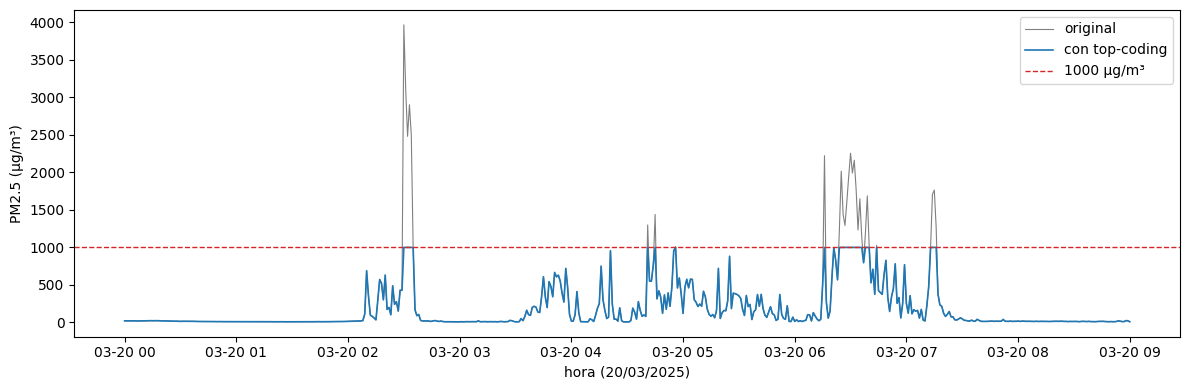

In [7]:
import matplotlib.pyplot as plt

ep = df[(df["estacion"] == "Curva de Maroñas") &
        (df["timestamp"].between("2025-03-20 00:00", "2025-03-20 09:00"))]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ep["timestamp"], ep["valor"], color="gray", lw=0.8, label="original")
ax.plot(ep["timestamp"], ep["valor_tc"], color="C0", lw=1.2, label="con top-coding")
ax.axhline(LIMITE, color="C3", ls="--", lw=1, label="1000 µg/m³")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_xlabel("hora (20/03/2025)"); ax.legend()
plt.tight_layout(); plt.savefig("fig_topcoding_20250320.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Agregación horaria
Los datos se agregan a frecuencia horaria sin imputar previamente los minutos faltantes. Una hora es válida si cuenta con al menos el 75 % de los registros esperados (45 de 60 en Curva de Maroñas y 23 de 30 en Museo Romántico). Las horas que no alcanzan ese porcentaje quedan como faltantes.

**Fuente:** Ministerio de Ambiente, *Guía DCA 04* — [Guia_Protocolo_tratamiento_estadistico_final_v2.pdf](https://www.ambiente.gub.uy/oan//documentos//Guia_Protocolo_tratamiento_estadistico_final_v2.pdf), p. 3.

In [8]:
MIN_VALIDOS = {"Curva de Maroñas": 45, "Museo Romántico": 23}

df["hora"] = df["timestamp"].dt.floor("h")
horario = (df.groupby(["estacion", "hora"])
           .agg(pm25=("valor_tc", "mean"),
                n_validos=("valor_tc", "count"),
                n_recortados=("recortado", "sum"))
           .reset_index())
horario["valida"] = horario["n_validos"] >= horario["estacion"].map(MIN_VALIDOS)
horario.loc[~horario["valida"], "pm25"] = np.nan

In [9]:
# Grilla horaria completa: las horas sin ningún registro quedan como faltantes
partes = []
for est, g in horario.groupby("estacion"):
    grilla = pd.date_range(g["hora"].min(), g["hora"].max(), freq="h", name="hora")
    g = g.set_index("hora").reindex(grilla)
    g["estacion"] = est
    g[["n_validos", "n_recortados"]] = g[["n_validos", "n_recortados"]].fillna(0).astype(int)
    g["valida"] = g["valida"].fillna(False).astype(bool)
    partes.append(g.reset_index())
horario = pd.concat(partes, ignore_index=True)

horario.groupby("estacion").agg(horas=("hora", "size"), validas=("valida", "sum"),
                                recortados=("n_recortados", "sum"))

/tmp/ipykernel_1021/1834946911.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  g["valida"] = g["valida"].fillna(False).astype(bool)
/tmp/ipykernel_1021/1834946911.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  g["valida"] = g["valida"].fillna(False).astype(bool)


,horas,validas,recortados
estacion,,,
Curva de Maroñas,21024,19773,41
Museo Romántico,3480,3451,0


## 6. Partición desarrollo/test
Se mantiene la partición de la propuesta: desarrollo de 2024 a 2025 y test final de enero a mayo de 2026. El test no interviene en ninguna decisión de preprocesamiento, selección de variables, modelos, rezagos o hiperparámetros. Museo Romántico se descargó únicamente para el período de test (enero a mayo de 2026), con el fin de evaluar la transferencia espacial del modelo.

In [10]:
CORTE = pd.Timestamp("2026-01-01", tz="America/Montevideo")
horario["particion"] = np.where(horario["hora"] < CORTE, "desarrollo", "test")

horario.groupby(["estacion", "particion"]).agg(
    inicio=("hora", "min"), fin=("hora", "max"),
    horas=("hora", "size"), validas=("valida", "sum"))

inicio  \
estacion         particion                              
Curva de Maroñas desarrollo 2024-01-01 00:00:00-03:00   
                 test       2026-01-01 00:00:00-03:00   
Museo Romántico  test       2026-01-01 00:00:00-03:00   

                                                  fin  horas  validas  
estacion         particion                                             
Curva de Maroñas desarrollo 2025-12-31 23:00:00-03:00  17544    16297  
                 test       2026-05-25 23:00:00-03:00   3480     3476  
Museo Romántico  test       2026-05-25 23:00:00-03:00   3480     3451

## 7. Tratamiento de faltantes horarios

**Antecedente y alternativa descartada.**
Karimian et al. (2019) interpolan los huecos de hasta 3 h y descartan del dataset las secuencias con más de 3 h consecutivas faltantes. Adoptamos el mismo límite de interpolación (3 h), pero no el descarte: al borrar filas, el rezago `k` deja de significar "hace k horas" y pasa a ser "k filas atrás". Tras un hueco, esa fila puede estar a decenas de horas de distancia, así que el modelo aprende transiciones que no ocurrieron y se desfasan los ciclos diario y semanal.

**Criterio adoptado.** Conservamos la grilla horaria completa y tratamos los faltantes según su duración:
- **Huecos de hasta 3 h:** se rellenan con interpolación lineal entre la última hora observada antes del hueco y la primera después. Solo se interpola entre dos valores reales, nunca se extrapola en los bordes de la serie. Así no se pierden ventanas de entrenamiento por faltantes triviales.
- **Huecos de más de 3 h:** permanecen como NaN, porque no hay datos observados que respalden un relleno y un hueco largo puede contener justo un episodio de contaminación.
- La interpolación se aplica por separado en desarrollo y en test, para que ningún dato de una partición influya en la otra.

**Cómo queda registrado.** Conservamos tres columnas:
- `pm25`: valor real, con NaN donde no hay dato válido.
- `pm25_modelo`: serie de entrada al modelo, con los huecos ≤3 h interpolados.
- `interpolada`: indica qué horas fueron rellenadas.

Las métricas se calculan solo sobre horas con dato real (`valida`), para no premiar al modelo por reproducir una interpolación.

**Cómo lo usa el modelo.** Como no eliminamos fechas ni unimos períodos, cada rezago `k` sigue significando "hace k horas". Con `dropna_from_series=True`, `skforecast` descarta solo las ventanas de entrenamiento que contienen NaN.

**Benchmark para elegir el método y analizar el límite de 3 h.**
1. Se toman tramos donde todos los valores son reales (6 h antes y 6 h después de cada ventana).
2. Se borran artificialmente 1, 2, 3 o 4 h consecutivas. Son valores que sí existen, así que conocemos la respuesta correcta.
3. Se reconstruyen con interpolación lineal, cuadrática y con la media del contexto.
4. Se mide el error contra el valor real (MAE) en todas las ventanas posibles.
5. Se grafican ejemplos para ver cómo queda cada interpolación.

La interpolación con menor error es la que se aplica en la serie. El benchmark permite elegir el método, pero no fija por sí solo el límite de longitud: el error crece de forma gradual con el tamaño del hueco. El límite de 3 h se adopta por consistencia con el antecedente citado, y su efecto sobre la serie se analiza en la sección 7.1.

In [11]:
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

K, GAPS = 6, (1, 2, 3, 4)         # K = horas de contexto a cada lado del hueco

# solo desarrollo y valores reales (pm25 con NaN donde no hay dato válido)
s = (horario[(horario["particion"] == "desarrollo") & (horario["estacion"] == "Curva de Maroñas")]
     .set_index("hora")["pm25"])
y = s.to_numpy()

def ventanas_validas(y, g, K):
    W = 2*K + g
    r = pd.Series(~np.isnan(y)).astype(int).rolling(W).sum().to_numpy()
    return np.where(r == W)[0] - W + 1          # inicio de cada ventana sin NaN

def interpolar(ctx, K, g):
    x = np.arange(2*K + g)
    xc, yc = np.r_[x[:K], x[K+g:]], np.r_[ctx[:K], ctx[K+g:]]   # contexto (sin el hueco)
    xg = x[K:K+g]
    lin = np.interp(xg, [K-1, K+g], [ctx[K-1], ctx[K+g]])
    cuad = interp1d(xc, yc, kind="quadratic")(xg)
    return lin, cuad, np.full(g, yc.mean())

# --- Error en todas las ventanas ---
filas = []
for g in GAPS:
    ini = ventanas_validas(y, g, K)
    err = {"lineal": [], "cuadratica": [], "media": []}
    for j in ini:
        ctx = y[j:j + 2*K + g]
        real = ctx[K:K + g]
        for n, p in zip(err, interpolar(ctx, K, g)):
            err[n].append(np.abs(p - real).mean())
    filas.append({"hueco_h": g, "ventanas": len(ini),
                  **{f"MAE_{k}": round(np.mean(v), 2) for k, v in err.items()},
                  "%_lineal_mejor_que_cuadratica": round(100*np.mean(np.array(err["lineal"]) < np.array(err["cuadratica"])), 1)})
pd.DataFrame(filas)

,hueco_h,ventanas,MAE_lineal,MAE_cuadratica,MAE_media,%_lineal_mejor_que_cuadratica
0,1,15917,3.36,3.68,7.00,58.7
1,2,15888,4.12,4.72,7.71,61.9
2,3,15859,4.83,5.73,8.31,62.9
3,4,15830,5.50,6.78,8.83,65.0


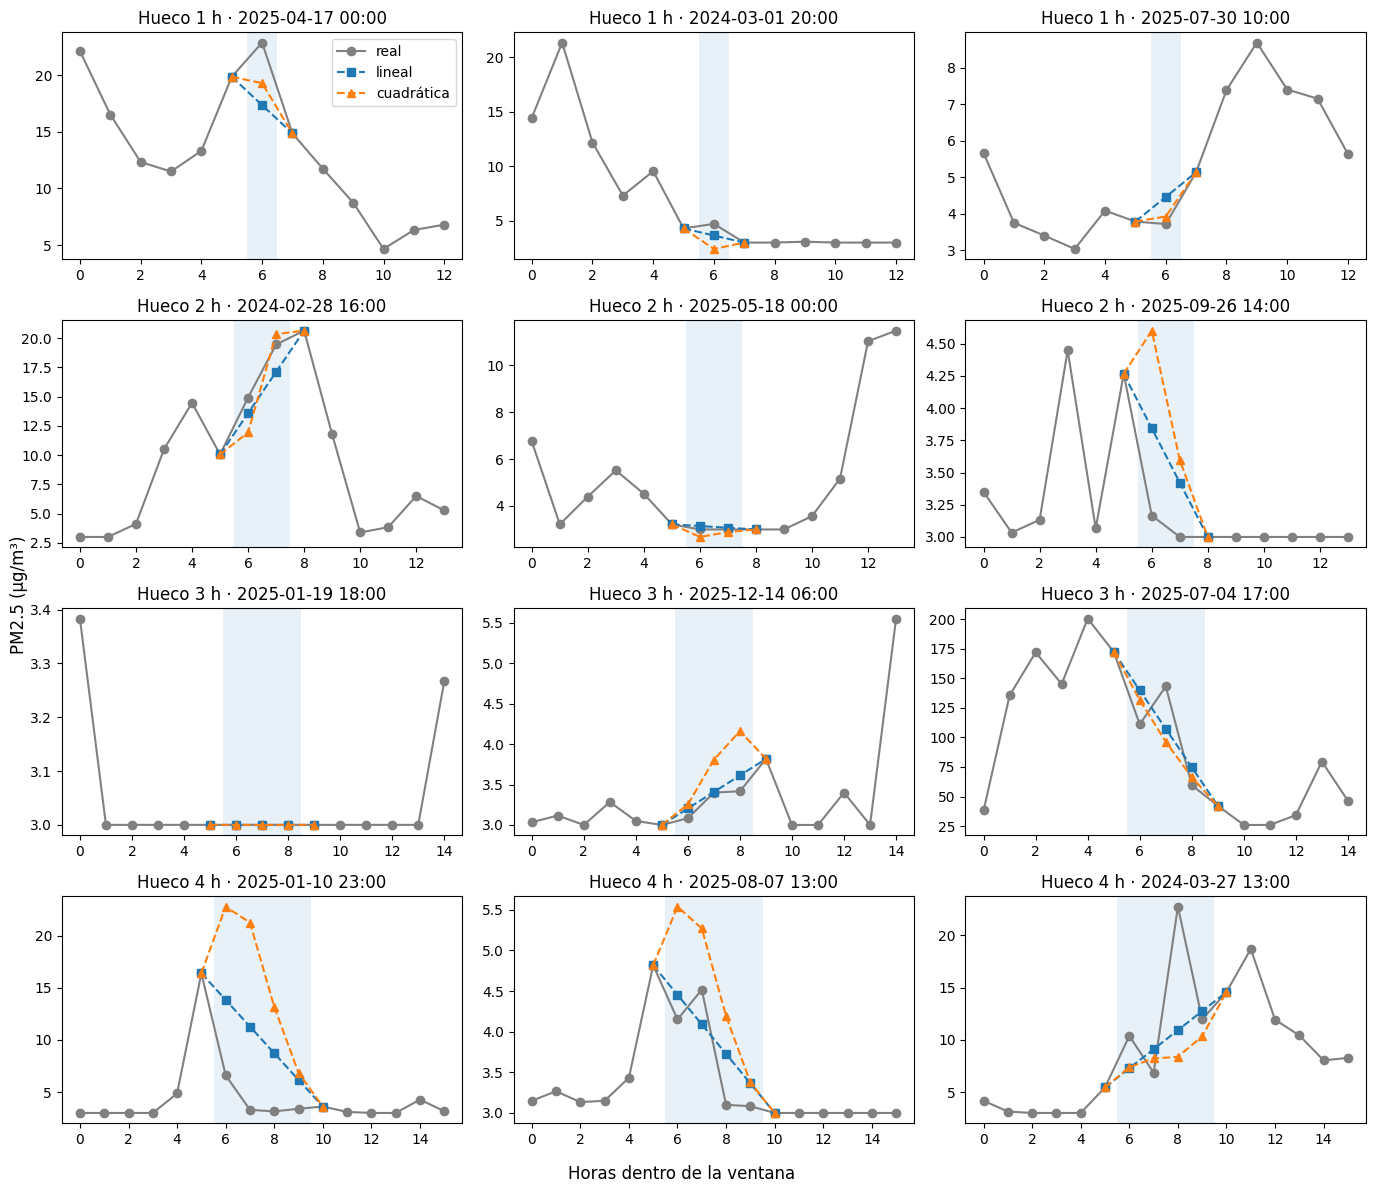

In [12]:
fig, axs = plt.subplots(len(GAPS), 3, figsize=(14, 3*len(GAPS)))
for f, g in enumerate(GAPS):
    ini = ventanas_validas(y, g, K)
    for c, j in enumerate(rng.choice(ini, 3, replace=False)):
        ctx = y[j:j + 2*K + g]
        x = np.arange(2*K + g)
        lin, cuad, _ = interpolar(ctx, K, g)
        xs = x[K-1:K+g+1]
        ax = axs[f, c]
        ax.plot(x, ctx, "o-", color="gray", label="real")
        ax.plot(xs, np.r_[ctx[K-1], lin, ctx[K+g]], "s--", label="lineal")
        ax.plot(xs, np.r_[ctx[K-1], cuad, ctx[K+g]], "^--", label="cuadrática")
        ax.axvspan(K-0.5, K+g-0.5, alpha=0.1)
        ax.set_title(f"Hueco {g} h · {s.index[j]:%Y-%m-%d %H:%M}")
axs[0, 0].legend()
fig.supxlabel("Horas dentro de la ventana"); fig.supylabel("PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

**Interpretación.** La interpolación lineal obtiene el menor MAE en los cuatro tamaños de hueco (3.36, 4.12, 4.83 y 5.50 µg/m³ para 1, 2, 3 y 4 h), frente a la cuadrática (3.68, 4.72, 5.73 y 6.78) y a la media del contexto (7.00, 7.71, 8.31 y 8.83), que en todos los casos supera ampliamente el error de la lineal. Esto indica que la dinámica local de la serie aporta información y que conviene usar los valores vecinos al hueco. La lineal supera a la cuadrática en el 58.7 %, 61.9 %, 62.9 % y 65.0 % de las ventanas: la ventaja no es abrumadora, pero es consistente y crece con la longitud del hueco, porque la cuadrática tiende a sobrepasar los valores sobre promedios horarios ruidosos. El error aumenta de forma gradual al alejarse de los datos observados (~0.7 µg/m³ por hora adicional), sin un salto que marque un corte natural, por lo que el benchmark permite elegir el método (interpolación lineal) pero no fija por sí solo el límite de longitud. Se adopta un límite de 3 h por consistencia con el antecedente citado (Karimian et al., 2019), dentro del rango en que la lineal se mantiene claramente mejor que la media del contexto.

In [13]:
MAX_HUECO_H = 3  # límite de interpolación (Karimian et al., 2019)

def interpolar_huecos_cortos(s, max_horas=MAX_HUECO_H):
    interp = s.interpolate(method="linear", limit_area="inside")
    nan = s.isna()
    bloque = nan.ne(nan.shift()).cumsum()
    largo = nan.groupby(bloque).transform("sum")
    return s.where(~(nan & (largo <= max_horas)), interp)

horario = horario.sort_values(["estacion", "hora"]).reset_index(drop=True)
horario["pm25_modelo"] = (horario.groupby(["estacion", "particion"])["pm25"]
                          .transform(interpolar_huecos_cortos))
horario["interpolada"] = horario["pm25"].isna() & horario["pm25_modelo"].notna()
horario.to_csv(DIR_PROC / "pm25_horario.csv", index=False)

La interpolación se aplicó por separado en desarrollo (2024–2025) y en test (2026), de modo que ninguna partición influye en la otra.

## 8. Resumen y verificación

In [14]:
# Grilla horaria regular y sin duplicados por estación
for est, g in horario.groupby("estacion"):
    assert g["hora"].is_unique and g["hora"].diff().dropna().eq(pd.Timedelta("1h")).all()

res = (horario.groupby(["estacion", "particion"])
       .agg(horas=("hora", "size"),
            validas=("valida", "sum"),
            interpoladas=("interpolada", "sum"),
            nan_restantes=("pm25_modelo", lambda s: s.isna().sum())))
for c in ["validas", "interpoladas", "nan_restantes"]:
    res[f"%_{c}"] = (100 * res[c] / res["horas"]).round(1)
res

horas  validas  interpoladas  nan_restantes  \
estacion         particion                                                 
Curva de Maroñas desarrollo  17544    16297            25           1222   
                 test         3480     3476             4              0   
Museo Romántico  test         3480     3451            18             11   

                             %_validas  %_interpoladas  %_nan_restantes  
estacion         particion                                               
Curva de Maroñas desarrollo       92.9             0.1              7.0  
                 test             99.9             0.1              0.0  
Museo Romántico  test             99.2             0.5              0.3

el 92.9 % de las horas de Curva en desarrollo son válidas, la interpolación aporta solo 22 horas y el 7 % restante queda como faltante en huecos largos.

In [15]:
from google.colab import files
files.download("data/processed/pm25_horario.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>